In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import joblib

In [3]:
df = pd.read_csv("Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (150, 6)


In [5]:
print("Column names:")
print(df.columns)

Column names:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [7]:
df.tail()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica
149,150,5.9,3.0,5.1,1.8,Iris-virginica


In [8]:
print(df["Species"].value_counts())

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [9]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [12]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (150, 6)


In [13]:
numeric_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    print(column, ":", len(outliers), "outliers")

SepalLengthCm : 0 outliers
SepalWidthCm : 4 outliers
PetalLengthCm : 0 outliers
PetalWidthCm : 0 outliers


In [14]:
df = df.drop("Id", axis=1)

df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [16]:
X_class = df.drop("Species", axis=1)
y_class = df["Species"]

In [17]:
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training samples:", len(X_train_class))
print("Testing samples:", len(X_test_class))

Training samples: 120
Testing samples: 30


In [18]:
dt_pipeline = Pipeline([
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        max_depth=4
    ))
])

dt_pipeline.fit(X_train_class, y_train_class)

,steps,"[('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None


In [19]:
y_pred_class = dt_pipeline.predict(X_test_class)

print(y_pred_class)

['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']


In [20]:
accuracy = accuracy_score(y_test_class, y_pred_class)

print("Decision Tree Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Decision Tree Accuracy: 0.9333333333333333
Accuracy Percentage: 93.33333333333333 %


In [21]:
print(classification_report(y_test_class, y_pred_class))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



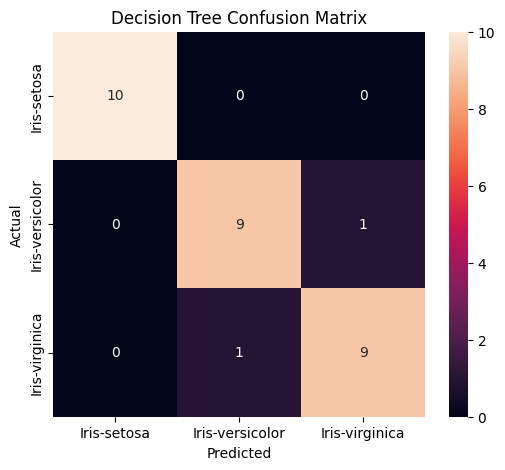

In [22]:
cm = confusion_matrix(y_test_class, y_pred_class)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=dt_pipeline.classes_,
    yticklabels=dt_pipeline.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [23]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X_class.columns
)

prediction = dt_pipeline.predict(new_flower)

print("Predicted Iris Species:", prediction[0])

Predicted Iris Species: Iris-setosa


In [24]:
X_reg = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalWidthCm"
    ]
]

y_reg = df["PetalLengthCm"]

In [25]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train_reg))
print("Testing samples:", len(X_test_reg))

Training samples: 120
Testing samples: 30


In [26]:
lr_pipeline = Pipeline([
    ("regressor", LinearRegression())
])

In [27]:
lr_pipeline.fit(X_train_reg, y_train_reg)

,steps,"[('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [28]:
y_pred_reg = lr_pipeline.predict(X_test_reg)

print(y_pred_reg)

[4.12907977 1.87775771 7.02910351 4.43236278 4.92926532 2.0639232
 3.84942915 6.12878356 5.02657149 3.97602415 5.33502143 1.44630795
 1.7788798  1.45452896 1.44325388 4.5394617  5.75667844 3.81294994
 3.98604275 5.81265373 1.39213025 4.8804804  1.77425398 5.66602153
 5.96368591 6.04814525 5.63596573 5.99216996 1.73957236 1.52874386]


In [29]:
mae = mean_absolute_error(y_test_reg, y_pred_reg)

mse = mean_squared_error(y_test_reg, y_pred_reg)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_reg, y_pred_reg)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Mean Absolute Error: 0.2606173239288886
Mean Squared Error: 0.12991981605759947
Root Mean Squared Error: 0.3604439152733744
R² Score: 0.9603587427485161


In [30]:
new_flower_reg = pd.DataFrame(
    [[5.9, 3.0, 1.8]],
    columns=[
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalWidthCm"
    ]
)

predicted_petal_length = lr_pipeline.predict(new_flower_reg)

print(
    "Predicted Petal Length:",
    predicted_petal_length[0],
    "cm"
)

Predicted Petal Length: 4.735645786566966 cm


In [31]:
joblib.dump(dt_pipeline, "iris_decision_tree.pkl")
joblib.dump(lr_pipeline, "iris_linear_regression.pkl")

print("Both models saved successfully.")

Both models saved successfully.


In [ ]:
loaded_dt_model = joblib.load("iris_decision_tree.pkl")
loaded_lr_model = joblib.load("iris_linear_regression.pkl")

In [ ]:
print(
    "Classification:",
    loaded_dt_model.predict(new_flower)[0]
)

print(
    "Predicted Petal Length:",
    loaded_lr_model.predict(new_flower_reg)[0],
    "cm"
)

Classification: Iris-setosa
Predicted Petal Length: 4.735645786566966 cm
